# **Step 1 - Set up the Python analysis notebook**

# 1.1 Import required libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1.2 Connect Google Drive

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1.3 Set the project path

In [7]:
project_path = '/content/drive/MyDrive/Brazilian e_commerce'

modeled_path = os.path.join(project_path, 'modeled')

print("Project path:", project_path)
print("Modeled path:", modeled_path)

print("\nFiles in modeled folder:")
print(os.listdir(modeled_path))

Project path: /content/drive/MyDrive/Brazilian e_commerce
Modeled path: /content/drive/MyDrive/Brazilian e_commerce/modeled

Files in modeled folder:
['dim_customer.csv', 'dim_product.csv', 'dim_seller.csv', 'dim_date.csv', 'fact_orders.csv', 'fact_order_items.csv', 'fact_payments.csv', 'fact_reviews.csv']


# **Step 2 – Load the modeled datasets**

In [8]:
dim_customer = pd.read_csv(os.path.join(modeled_path, 'dim_customer.csv'))
dim_product = pd.read_csv(os.path.join(modeled_path, 'dim_product.csv'))
dim_seller = pd.read_csv(os.path.join(modeled_path, 'dim_seller.csv'))
dim_date = pd.read_csv(os.path.join(modeled_path, 'dim_date.csv'))

fact_orders = pd.read_csv(os.path.join(modeled_path, 'fact_orders.csv'))
fact_order_items = pd.read_csv(os.path.join(modeled_path, 'fact_order_items.csv'))
fact_payments = pd.read_csv(os.path.join(modeled_path, 'fact_payments.csv'))
fact_reviews = pd.read_csv(os.path.join(modeled_path, 'fact_reviews.csv'))

# 2.1 Check dataset dimensions

In [9]:
datasets = {
    'dim_customer': dim_customer,
    'dim_product': dim_product,
    'dim_seller': dim_seller,
    'dim_date': dim_date,
    'fact_orders': fact_orders,
    'fact_order_items': fact_order_items,
    'fact_payments': fact_payments,
    'fact_reviews': fact_reviews
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

dim_customer: (96096, 1)
dim_product: (32951, 10)
dim_seller: (3095, 4)
dim_date: (1096, 8)
fact_orders: (99441, 13)
fact_order_items: (112650, 9)
fact_payments: (103886, 6)
fact_reviews: (99224, 9)


# 2.2 Check data types

In [10]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.dtypes)


dim_customer
customer_unique_id    object
dtype: object

dim_product
product_id                        object
product_category_name             object
product_category_name_english     object
product_name_length              float64
product_description_length       float64
product_photos_qty               float64
product_weight_g                 float64
product_length_cm                float64
product_height_cm                float64
product_width_cm                 float64
dtype: object

dim_seller
seller_id                 object
seller_zip_code_prefix     int64
seller_city               object
seller_state              object
dtype: object

dim_date
date                  object
year                   int64
month_number           int64
month_name            object
quarter                int64
day                    int64
day_of_week           object
day_of_week_number     int64
dtype: object

fact_orders
order_id                         object
customer_id                      object

# 2.3 Convert date columns

In [11]:
order_date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in order_date_columns:
    fact_orders[col] = pd.to_datetime(fact_orders[col], errors='coerce')

fact_order_items['shipping_limit_date'] = pd.to_datetime(
    fact_order_items['shipping_limit_date'], errors='coerce'
)

fact_reviews['review_creation_date'] = pd.to_datetime(
    fact_reviews['review_creation_date'], errors='coerce'
)

fact_reviews['review_answer_timestamp'] = pd.to_datetime(
    fact_reviews['review_answer_timestamp'], errors='coerce'
)

dim_date['date'] = pd.to_datetime(dim_date['date'], errors='coerce')

# 2.4 Check missing values

In [12]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum())


dim_customer
customer_unique_id    0
dtype: int64

dim_product
product_id                         0
product_category_name              0
product_category_name_english      0
product_name_length              610
product_description_length       610
product_photos_qty               610
product_weight_g                   2
product_length_cm                  2
product_height_cm                  2
product_width_cm                   2
dtype: int64

dim_seller
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

dim_date
date                  0
year                  0
month_number          0
month_name            0
quarter               0
day                   0
day_of_week           0
day_of_week_number    0
dtype: int64

fact_orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 16

# **Step 3 – Prepare delivery status**

# **Business Question 1 – Does late delivery affect customer review scores?**

In [13]:
delivery_df = fact_orders[
    fact_orders['order_status'] == 'delivered'
].copy()

delivery_df = delivery_df.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
)

delivery_df['actual_delivery_date'] = (
    delivery_df['order_delivered_customer_date'].dt.date
)

delivery_df['estimated_delivery_date'] = (
    delivery_df['order_estimated_delivery_date'].dt.date
)

delivery_df['delivery_status'] = np.where(
    delivery_df['actual_delivery_date'] >
    delivery_df['estimated_delivery_date'],
    'Late',
    'On Time'
)

delivery_df['delay_days'] = (
    delivery_df['order_delivered_customer_date'].dt.normalize() -
    delivery_df['order_estimated_delivery_date'].dt.normalize()
).dt.days.clip(lower=0)

print(delivery_df['delivery_status'].value_counts())

delivery_status
On Time    89936
Late        6534
Name: count, dtype: int64


# **Step 4 – Merge reviews with delivery information**

In [14]:
satisfaction_df = delivery_df[
    ['order_id', 'delivery_status', 'delay_days']
].merge(
    fact_reviews[['order_id', 'review_score']],
    on='order_id',
    how='inner'
)

print(satisfaction_df.head())
print("Total review records:", len(satisfaction_df))

                           order_id delivery_status  delay_days  review_score
0  e481f51cbdc54678b7cc49136f2d6af7         On Time           0             4
1  53cdb2fc8bc7dce0b6741e2150273451         On Time           0             4
2  47770eb9100c2d0c44946d9cf07ec65d         On Time           0             5
3  949d5b44dbf5de918fe9c16f97b45f8a         On Time           0             5
4  ad21c59c0840e6cb83a9ceb5573f8159         On Time           0             5
Total review records: 96353


# **Step 5 – Compare review scores**

In [15]:
satisfaction_summary = satisfaction_df.groupby(
    'delivery_status'
).agg(
    total_reviews=('review_score', 'count'),
    average_review_score=('review_score', 'mean'),
    negative_reviews=('review_score', lambda x: (x <= 2).sum()),
    positive_reviews=('review_score', lambda x: (x >= 4).sum())
).reset_index()

satisfaction_summary['negative_review_percentage'] = (
    satisfaction_summary['negative_reviews'] /
    satisfaction_summary['total_reviews'] * 100
)

satisfaction_summary['positive_review_percentage'] = (
    satisfaction_summary['positive_reviews'] /
    satisfaction_summary['total_reviews'] * 100
)

print(satisfaction_summary.round(2))

  delivery_status  total_reviews  average_review_score  negative_reviews  \
0            Late           6409                  2.27              4000   
1         On Time          89944                  4.29              8346   

   positive_reviews  negative_review_percentage  positive_review_percentage  
0              1712                       62.41                       26.71  
1             74334                        9.28                       82.64  


# **Step 6 – Visualize customer satisfaction**

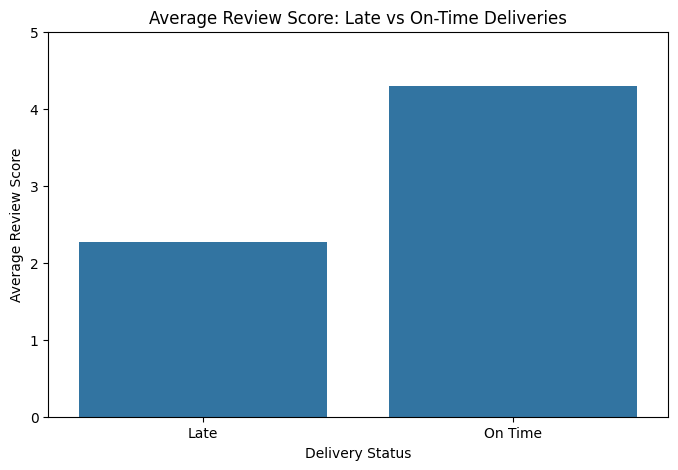

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=satisfaction_summary,
    x='delivery_status',
    y='average_review_score'
)

plt.title('Average Review Score: Late vs On-Time Deliveries')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.show()

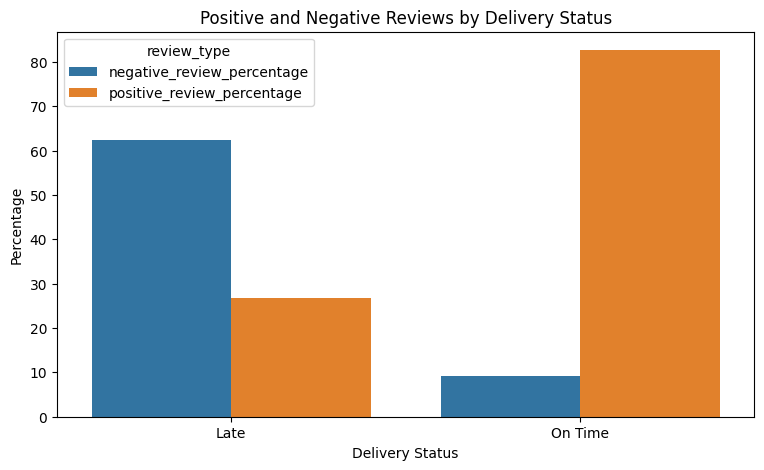

In [17]:
satisfaction_plot = satisfaction_summary.melt(
    id_vars='delivery_status',
    value_vars=[
        'negative_review_percentage',
        'positive_review_percentage'
    ],
    var_name='review_type',
    value_name='percentage'
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=satisfaction_plot,
    x='delivery_status',
    y='percentage',
    hue='review_type'
)

plt.title('Positive and Negative Reviews by Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Percentage')
plt.show()

# **Step 7 – Calculate state-wise delivery performance**

# **Business Question 2 – Which geographical regions experience the highest delivery delays?**

In [18]:
state_delivery = delivery_df.groupby('customer_state').agg(
    total_delivered_orders=('order_id', 'nunique'),
    late_orders=('delivery_status', lambda x: (x == 'Late').sum()),
    average_delay_days=('delay_days', 'mean')
).reset_index()

state_delivery['late_delivery_percentage'] = (
    state_delivery['late_orders'] /
    state_delivery['total_delivered_orders'] * 100
)

state_delivery = state_delivery.sort_values(
    'late_delivery_percentage',
    ascending=False
)

print(state_delivery.round(2))

   customer_state  total_delivered_orders  late_orders  average_delay_days  \
1              AL                     397           85                2.04   
9              MA                     717          125                1.83   
24             SE                     335           51                2.47   
16             PI                     476           66                1.85   
5              CE                    1279          176                2.09   
21             RR                      41            5                4.44   
4              BA                    3256          396                1.46   
18             RJ                   12350         1495                1.64   
13             PA                     946          106                1.44   
7              ES                    1995          214                1.21   
14             PB                     517           54                1.08   
26             TO                     274           27          

# **Step 8 – Visualize state-wise delays**

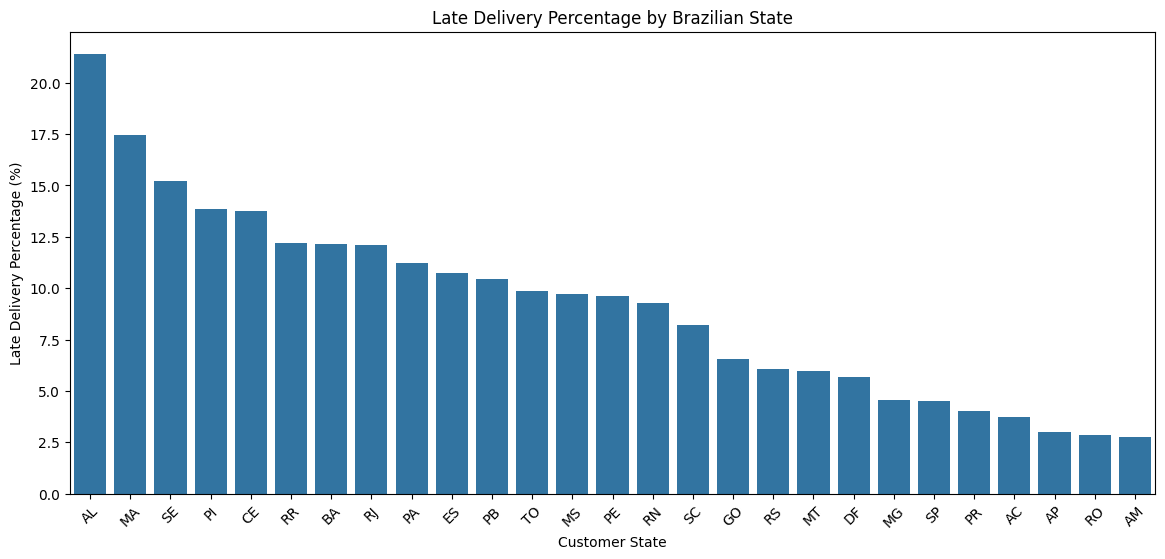

In [19]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=state_delivery,
    x='customer_state',
    y='late_delivery_percentage'
)

plt.title('Late Delivery Percentage by Brazilian State')
plt.xlabel('Customer State')
plt.ylabel('Late Delivery Percentage (%)')
plt.xticks(rotation=45)
plt.show()

# **Business Question 3 – Which product categories and sellers generate the highest revenue?**

# **Step 9 – Analyse product category revenue**

In [20]:
valid_orders = fact_orders[
    ~fact_orders['order_status'].isin(['canceled', 'unavailable'])
][['order_id', 'order_status']]

revenue_items = fact_order_items.merge(
    valid_orders,
    on='order_id',
    how='inner'
)

category_revenue = revenue_items.merge(
    dim_product[['product_id', 'product_category_name_english']],
    on='product_id',
    how='left'
)

category_revenue_summary = category_revenue.groupby(
    'product_category_name_english'
).agg(
    total_revenue=('price', 'sum'),
    total_items=('order_item_id', 'count')
).reset_index()

category_revenue_summary = category_revenue_summary.sort_values(
    'total_revenue',
    ascending=False
)

category_revenue_summary['revenue_percentage'] = (
    category_revenue_summary['total_revenue'] /
    category_revenue_summary['total_revenue'].sum() * 100
)

print(category_revenue_summary.head(15).round(2))

   product_category_name_english  total_revenue  total_items  \
44                 health_beauty     1255695.13         9634   
73                 watches_gifts     1198185.21         5970   
7                 bed_bath_table     1035964.06        11097   
67                sports_leisure      979740.92         8590   
15         computers_accessories      904322.02         7781   
39               furniture_decor      727465.05         8298   
50                    housewares      626825.80         6915   
20                    cool_stuff      620770.49         3779   
5                           auto      586585.73         4204   
43                  garden_tools      481009.94         4328   
71                          toys      479808.54         4083   
6                           baby      410312.20         3043   
61                     perfumery      396599.31         3402   
70                     telephony      322342.64         4527   
59              office_furniture      27

# **Step 10 – Visualize top product categories**

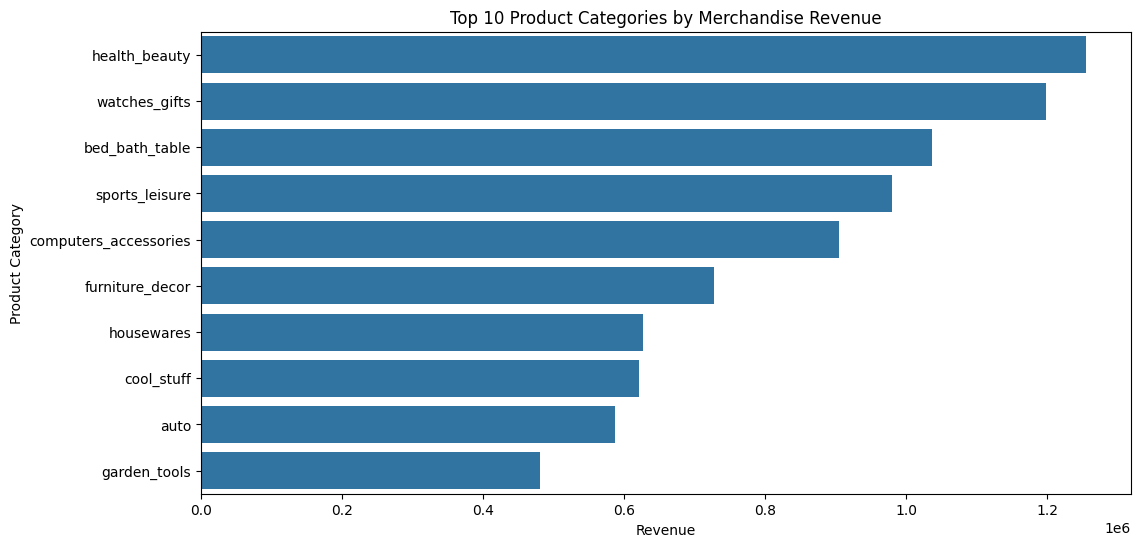

In [21]:
top_categories = category_revenue_summary.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x='total_revenue',
    y='product_category_name_english'
)

plt.title('Top 10 Product Categories by Merchandise Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product Category')
plt.show()

# **Step 11 – Analyse seller revenue**

In [22]:
seller_revenue = revenue_items.groupby('seller_id').agg(
    total_revenue=('price', 'sum'),
    total_items=('order_item_id', 'count')
).reset_index()

seller_revenue = seller_revenue.sort_values(
    'total_revenue',
    ascending=False
)

seller_revenue['revenue_percentage'] = (
    seller_revenue['total_revenue'] /
    seller_revenue['total_revenue'].sum() * 100
)

print(seller_revenue.head(15).round(2))

                             seller_id  total_revenue  total_items  \
849   4869f7a5dfa277a7dca6462dcf3b52b2      229237.63         1155   
1000  53243585a1d6dc2643021fd1853d8905      222776.05          410   
873   4a3ca9315b744ce9f8e9374361493884      200326.12         1985   
2984  fa1c13f2614d7b5c4749cbc52fecda94      192842.13          585   
1515  7c67e1448b00f6e969d365cea6b010ab      187923.89         1364   
1540  7e93a43ef30c4f03f38b393420bc753a      172583.88          336   
2611  da8622b14eb17ae2831f4ac5b9dab84a      160236.57         1551   
1485  7a67c85e85bb2ce8582c35f2203ad736      141715.54         1170   
191   1025f0e2d44d7041d6cf58b6550e0bfa      138968.55         1428   
1799  955fee9216a65b617aa5c0531780ce60      135159.70         1498   
835   46dc3b2cc0980fb8ec44634e21d2718e      127161.22          539   
1219  6560211a19b47992c3666cc44a7e94c0      122776.83         2025   
1182  620c87c171fb2a6dd6e8bb4dec959fc6      113659.40          789   
1520  7d13fca1522535

# **Step 12 – Visualize top sellers**

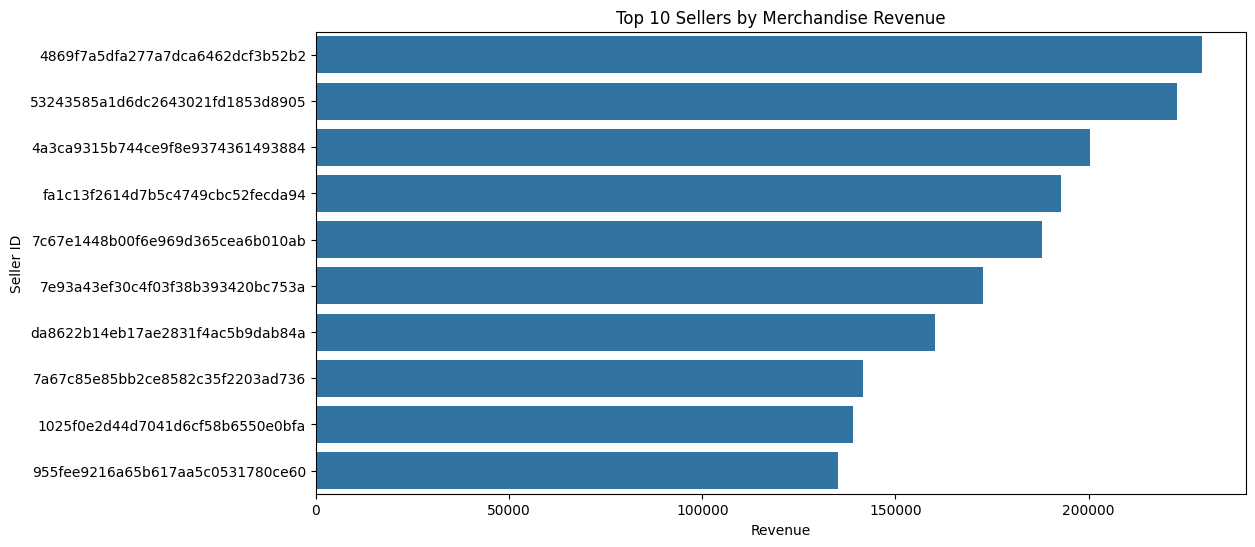

In [23]:
top_sellers = seller_revenue.head(10).copy()

top_sellers['seller_id'] = top_sellers['seller_id'].astype(str)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sellers,
    x='total_revenue',
    y='seller_id'
)

plt.title('Top 10 Sellers by Merchandise Revenue')
plt.xlabel('Revenue')
plt.ylabel('Seller ID')
plt.show()

# **Step 13 – Check revenue concentration**

In [24]:
top_10_category_share = category_revenue_summary.head(10)[
    'total_revenue'
].sum() / category_revenue_summary['total_revenue'].sum() * 100

top_10_seller_share = seller_revenue.head(10)[
    'total_revenue'
].sum() / seller_revenue['total_revenue'].sum() * 100

print("Top 10 category revenue share:", round(top_10_category_share, 2), "%")
print("Top 10 seller revenue share:", round(top_10_seller_share, 2), "%")

Top 10 category revenue share: 62.37 %
Top 10 seller revenue share: 13.2 %


# **Business Question 4 – Which payment methods are most popular, and how does order value differ between them?**

# **Step 14 – Analyse payment methods**

In [25]:
payment_summary = fact_payments.groupby('payment_type').agg(
    total_payment_records=('payment_type', 'count'),
    total_payment_value=('payment_value', 'sum'),
    average_payment_amount=('payment_value', 'mean'),
    total_installments=('payment_installments', 'mean')
).reset_index()

payment_summary['payment_value_percentage'] = (
    payment_summary['total_payment_value'] /
    payment_summary['total_payment_value'].sum() * 100
)

payment_summary = payment_summary.sort_values(
    'total_payment_value',
    ascending=False
)

print(payment_summary.round(2))

  payment_type  total_payment_records  total_payment_value  \
1  credit_card                  76795          12542084.19   
0       boleto                  19784           2869361.27   
4      voucher                   5775            379436.87   
2   debit_card                   1529            217989.79   
3  not_defined                      3                 0.00   

   average_payment_amount  total_installments  payment_value_percentage  
1                  163.32                3.51                     78.34  
0                  145.03                1.00                     17.92  
4                   65.70                1.00                      2.37  
2                  142.57                1.00                      1.36  
3                    0.00                1.00                      0.00  


# **Step 15 – Visualize payment popularity**

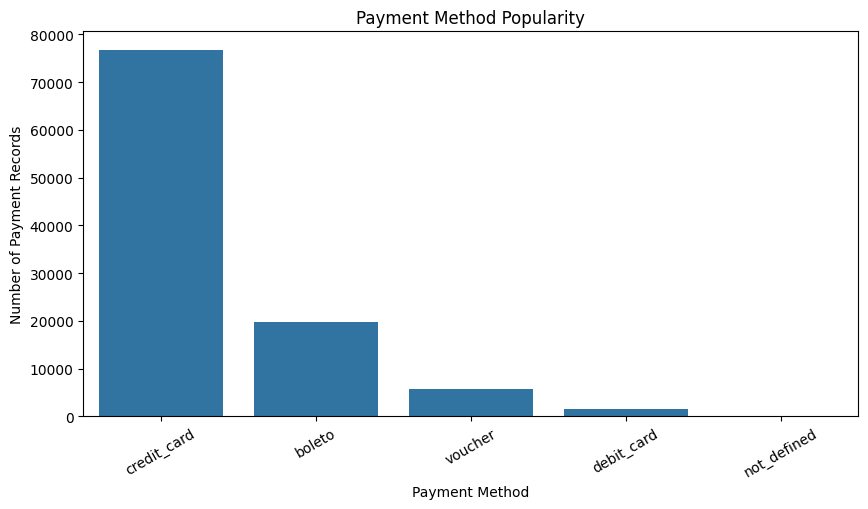

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_summary,
    x='payment_type',
    y='total_payment_records'
)

plt.title('Payment Method Popularity')
plt.xlabel('Payment Method')
plt.ylabel('Number of Payment Records')
plt.xticks(rotation=30)
plt.show()

# **Step 16 – Visualize total payment value**

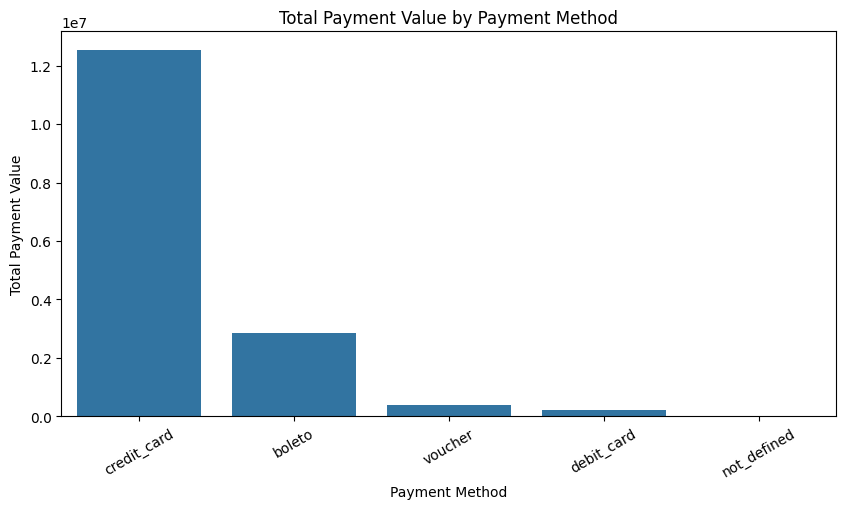

In [27]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_summary,
    x='payment_type',
    y='total_payment_value'
)

plt.title('Total Payment Value by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Payment Value')
plt.xticks(rotation=30)
plt.show()

# **Step 17 – Compare average payment amount**

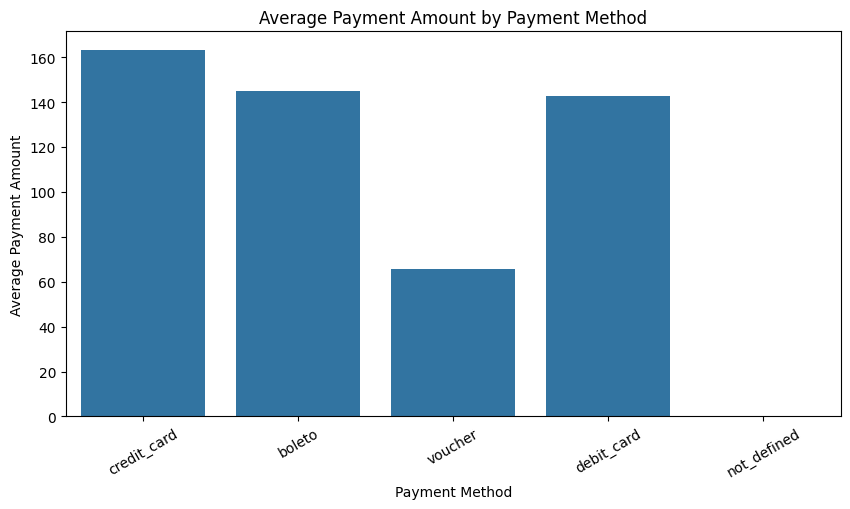

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_summary,
    x='payment_type',
    y='average_payment_amount'
)

plt.title('Average Payment Amount by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Average Payment Amount')
plt.xticks(rotation=30)
plt.show()

# **Business Question 5 – Which operational area should management prioritize for improvement?**

# **Step 18 – Create an overall delivery summary**

In [29]:
overall_delivery_summary = delivery_df.groupby(
    'delivery_status'
).agg(
    total_orders=('order_id', 'nunique'),
    average_delay_days=('delay_days', 'mean')
).reset_index()

overall_delivery_summary['order_percentage'] = (
    overall_delivery_summary['total_orders'] /
    overall_delivery_summary['total_orders'].sum() * 100
)

print(overall_delivery_summary.round(2))

  delivery_status  total_orders  average_delay_days  order_percentage
0            Late          6534               10.62              6.77
1         On Time         89936                0.00             93.23


# **Step 19 – Combine delivery and customer satisfaction**

In [30]:
operational_summary = satisfaction_df.groupby(
    'delivery_status'
).agg(
    total_reviews=('review_score', 'count'),
    average_review_score=('review_score', 'mean'),
    negative_review_percentage=(
        'review_score',
        lambda x: (x <= 2).mean() * 100
    )
).reset_index()

print(operational_summary.round(2))

  delivery_status  total_reviews  average_review_score  \
0            Late           6409                  2.27   
1         On Time          89944                  4.29   

   negative_review_percentage  
0                       62.41  
1                        9.28  


# **Step 20 – Identify the states with the highest delays**

In [31]:
print(
    state_delivery[
        [
            'customer_state',
            'total_delivered_orders',
            'late_delivery_percentage',
            'average_delay_days'
        ]
    ].head(10).round(2)
)

   customer_state  total_delivered_orders  late_delivery_percentage  \
1              AL                     397                     21.41   
9              MA                     717                     17.43   
24             SE                     335                     15.22   
16             PI                     476                     13.87   
5              CE                    1279                     13.76   
21             RR                      41                     12.20   
4              BA                    3256                     12.16   
18             RJ                   12350                     12.11   
13             PA                     946                     11.21   
7              ES                    1995                     10.73   

    average_delay_days  
1                 2.04  
9                 1.83  
24                2.47  
16                1.85  
5                 2.09  
21                4.44  
4                 1.46  
18                

# **Step 21 – Create a final business findings summary**

In [32]:
late_percentage = (
    delivery_df['delivery_status'].eq('Late').mean() * 100
)

on_time_percentage = (
    delivery_df['delivery_status'].eq('On Time').mean() * 100
)

print("FINAL BUSINESS PERFORMANCE SUMMARY")
print("-----------------------------------")

print("Total delivered orders analysed:", len(delivery_df))

print("Late delivery percentage:", round(late_percentage, 2), "%")

print("On-time delivery percentage:", round(on_time_percentage, 2), "%")

print("Top revenue category:",
      category_revenue_summary.iloc[0]['product_category_name_english'])

print("Top revenue seller:",
      seller_revenue.iloc[0]['seller_id'])

print("Most used payment method:",
      payment_summary.sort_values(
          'total_payment_records',
          ascending=False
      ).iloc[0]['payment_type'])

print("State with highest late delivery percentage:",
      state_delivery.iloc[0]['customer_state'])

FINAL BUSINESS PERFORMANCE SUMMARY
-----------------------------------
Total delivered orders analysed: 96470
Late delivery percentage: 6.77 %
On-time delivery percentage: 93.23 %
Top revenue category: health_beauty
Top revenue seller: 4869f7a5dfa277a7dca6462dcf3b52b2
Most used payment method: credit_card
State with highest late delivery percentage: AL


# **Step 22 – Save the analysis outputs**

In [33]:
analysis_path = os.path.join(project_path, 'python_outputs')

os.makedirs(analysis_path, exist_ok=True)

satisfaction_summary.to_csv(
    os.path.join(analysis_path, 'satisfaction_summary.csv'),
    index=False
)

state_delivery.to_csv(
    os.path.join(analysis_path, 'state_delivery_summary.csv'),
    index=False
)

category_revenue_summary.to_csv(
    os.path.join(analysis_path, 'category_revenue_summary.csv'),
    index=False
)

seller_revenue.to_csv(
    os.path.join(analysis_path, 'seller_revenue_summary.csv'),
    index=False
)

payment_summary.to_csv(
    os.path.join(analysis_path, 'payment_summary.csv'),
    index=False
)

overall_delivery_summary.to_csv(
    os.path.join(analysis_path, 'overall_delivery_summary.csv'),
    index=False
)

operational_summary.to_csv(
    os.path.join(analysis_path, 'operational_summary.csv'),
    index=False
)

print("All analysis output files saved successfully!")

All analysis output files saved successfully!


# **Statistical Hypothesis Testing – Delivery Delay and Customer Satisfaction**

In [34]:
# ============================================
# CHI-SQUARE TEST OF INDEPENDENCE
# Delivery Status vs Review Rating
# ============================================

import pandas as pd
from scipy.stats import chi2_contingency

# 1. Prepare order delivery information
orders_test = fact_orders[
    [
        'order_id',
        'order_status',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
].copy()

orders_test['order_delivered_customer_date'] = pd.to_datetime(
    orders_test['order_delivered_customer_date'],
    errors='coerce'
)

orders_test['order_estimated_delivery_date'] = pd.to_datetime(
    orders_test['order_estimated_delivery_date'],
    errors='coerce'
)

# Keep delivered orders with valid dates
orders_test = orders_test[
    (orders_test['order_status'] == 'delivered') &
    orders_test['order_delivered_customer_date'].notna() &
    orders_test['order_estimated_delivery_date'].notna()
].copy()

# 2. Classify delivery status
orders_test['delivery_group'] = (
    orders_test['order_delivered_customer_date'] >
    orders_test['order_estimated_delivery_date']
).map({
    True: 'Late',
    False: 'On Time'
})

# 3. Prepare review data
reviews_test = fact_reviews[
    ['order_id', 'review_score']
].dropna().copy()

# One average review score per order
reviews_test = (
    reviews_test.groupby('order_id', as_index=False)
    ['review_score'].mean()
)

# Convert average score into rating categories
reviews_test['rating_group'] = pd.cut(
    reviews_test['review_score'],
    bins=[0, 2, 3, 5],
    labels=['Low (1-2)', 'Neutral (3)', 'High (4-5)'],
    include_lowest=True
)

# 4. Combine the datasets
test_data = orders_test[
    ['order_id', 'delivery_group']
].merge(
    reviews_test[['order_id', 'rating_group']],
    on='order_id',
    how='inner'
)

# 5. Create contingency table
contingency_table = pd.crosstab(
    test_data['delivery_group'],
    test_data['rating_group']
)

print("CONTINGENCY TABLE")
print(contingency_table)

# 6. Perform Chi-square test
chi2, p_value, degrees_of_freedom, expected = (
    chi2_contingency(contingency_table)
)

print("\nCHI-SQUARE TEST RESULTS")
print("------------------------------")
print("Chi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", degrees_of_freedom)
print("P-value:", p_value)
print("Significance level: 0.05")

print("\nEXPECTED FREQUENCIES")
print(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
).round(2))

# 7. Check assumptions
print("\nMinimum expected frequency:", round(expected.min(), 2))
print(
    "Expected cells below 5:",
    (expected < 5).sum(),
    "out of",
    expected.size
)

# 8. Interpret the result
if (expected < 5).any():
    print("\nWarning: Some expected cell counts are below 5.")
    print("The Chi-square approximation may not be reliable.")

alpha = 0.05

if p_value < alpha:
    print("\nConclusion: Reject the null hypothesis.")
    print(
        "There is a statistically significant association "
        "between delivery status and review rating."
    )
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print(
        "There is insufficient evidence of an association "
        "between delivery status and review rating."
    )

CONTINGENCY TABLE
rating_group    Low (1-2)  Neutral (3)  High (4-5)
delivery_group                                    
Late                 4136          874        2651
On Time              8100         7071       72992

CHI-SQUARE TEST RESULTS
------------------------------
Chi-square statistic: 13249.786
Degrees of freedom: 2
P-value: 0.0
Significance level: 0.05

EXPECTED FREQUENCIES
rating_group    Low (1-2)  Neutral (3)  High (4-5)
delivery_group                                    
Late               978.25       635.19     6047.56
On Time          11257.75      7309.81    69595.44

Minimum expected frequency: 635.19
Expected cells below 5: 0 out of 6

Conclusion: Reject the null hypothesis.
There is a statistically significant association between delivery status and review rating.


## Statistical Hypothesis Testing: Delivery Status and Customer Satisfaction

**Objective:** To determine whether there is a statistically significant association between delivery status and customer review ratings.

**Test used:** Chi-square test of independence.

**Hypotheses:**
- H₀: Delivery status and customer review rating are independent.
- H₁: Delivery status and customer review rating are associated.

**Significance level:** 5% (α = 0.05).

**Results:**

The Chi-square test produced a statistic of 13,249.786 with 2 degrees of freedom and a p-value below 0.05. All expected cell frequencies were above 5, satisfying the expected-frequency condition for the test.

Therefore, the null hypothesis was rejected. There is a statistically significant association between delivery status and customer review rating.

Among late-delivered orders, approximately 54.02% received low ratings (1–2), compared with approximately 9.19% of on-time-delivered orders. Conversely, 82.79% of on-time-delivered orders received high ratings (4–5), compared with approximately 34.62% of late-delivered orders.

**Business interpretation:**

Late delivery is strongly associated with poorer customer ratings. Olist should investigate delivery delays and improve logistics coordination, delivery estimates, and communication with customers.

**Limitation:** This test identifies an association and does not establish that late delivery is the sole cause of lower customer ratings.